# Training-time estimates: AE, VAE, and MLP

MLP estimates follow the current decoder loader, including partial passes. Cell-count fits use dataset size and time per recorded epoch; FLOP-based architecture scaling uses the recorded LuCA workload. Epoch counts are estimated from the saved runs.

Two OLS regressions per family: 

- **cells -> s/epoch**
  - fit per family x latent
  - model complexity is 1024x1
- **TFLOPs -> s/epoch**
  - fit at latent 2048 for AE/VAE
  - fit at latent 2058 for MLP from SE

Epochs: median on full LuCA. Plus PCA and FM embedding extraction.


In [1]:
1

1

In [2]:
from pathlib import Path
from itertools import product
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display
%matplotlib inline

pd.set_option("display.max_rows", 30)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

ROOT = Path("..")


In [3]:
# -- Benchmark settings (edit here) ------------------------------------------
E2E_MODELS  = ["mlAE", "nlscVI"]
E2E_LATENTS = [10, 32, 128, 512, 2048]
FM_LATENTS  = {
    "scimilarity": 128, "scGPT": 512, "scConcept": 512,
    "Geneformer": 1152, "UCE": 1280, "SE": 2058, "scFoundation": 3072,
}
WIDTHS      = [1024, 2048, 4096]
DEPTHS      = [1, 2, 3, 4]

BATCH_SIZE = {  # training minibatch per dataset and family
    "LuCA":  {"AE": 256,  "VAE": 256,  "MLP": 256},
    "PBMC":  {"AE": 5000, "VAE": 5000, "MLP": 256},
    "Tahoe": {"AE": 1000, "VAE": 5000, "MLP": 5000},
}

# -- Lookups -----------------------------------------------------------------
MODEL_FAMILY = {"mlAE": "AE", "nlscVI": "VAE", **{m: "MLP" for m in FM_LATENTS}}
FLOPS_FIT_ON = {"AE": ("mlAE", 2048), "VAE": ("nlscVI", 2048), "MLP": ("SE", 2058)}  # (model, latent)
KEYS = ["model", "latent_dim", "hidden_dim", "depth"]
META = json.loads((ROOT / "runtime/01_end_to_end/flops/metadata.json").read_text())  # full-LuCA n_train, n_val
TIMING_BATCH = META["profile_batch_size"]  # minibatch of all timing runs (256)
PER_STEP_SHARE = 0.87  # share of intercept_2 that scales with 256 / B (from real PBMC / Tahoe runs)


## 1. Read runs

- s/epoch = wall time / epochs run
- averaged over repeats
- settings with < 3 repeats dropped


In [4]:
# Existing durations and epoch counts, exported once from the original run records.
complexity_measurements = pd.concat([
    pd.read_csv(ROOT / "runtime/01_end_to_end/measurements/complexity_runtime.csv"),
    pd.read_csv(ROOT / "runtime/02_foundation_model/measurements/complexity_runtime.csv"),
], ignore_index=True).set_index("run_dir", verify_integrity=True)


def load_run(run):
    # run_dir identifies the historical run; it is not opened as a filesystem path.
    if run["run_dir"] not in complexity_measurements.index:
        return None
    rec = complexity_measurements.loc[run["run_dir"]]
    if rec["exit_code"] != 0 or not rec["epochs"] > 0:
        return None
    assert all(rec[k] == run[k] for k in [*KEYS, "repeat"])
    is_mlp = run["model"] in FM_LATENTS
    if is_mlp and not all(pd.notna(rec.get(k)) for k in ("train_cells_per_epoch", "val_cells_per_epoch")):
        return None
    return {**{k: run[k] for k in [*KEYS, "repeat"]},
            "train_cells_per_epoch": rec["train_cells_per_epoch"] if is_mlp else rec["n_train"],
            "val_cells_per_epoch": rec["val_cells_per_epoch"] if is_mlp else np.nan,
            "n_train": rec["n_train"], "epochs": rec["epochs"],
            "seconds": rec["seconds"]}


In [5]:
COLS = [*KEYS, "repeat", "n_train", "epochs", "seconds",
        "train_cells_per_epoch", "val_cells_per_epoch"]

# -- Cell-count experiments: 1024x1 on LuCA subsets (CSV) --------------------
e2e = pd.read_csv(ROOT / "runtime/01_end_to_end/measurements/runtime.csv")
e2e = e2e[e2e.model.isin(E2E_MODELS) & (e2e.exit_code == 0)].assign(hidden_dim=1024, depth=1)
e2e = e2e.assign(train_cells_per_epoch=e2e.n_train, val_cells_per_epoch=np.nan)

fm = pd.read_csv(ROOT / "runtime/02_foundation_model/measurements/decoder_runtime.csv").rename(
    columns={"n_hidden": "hidden_dim", "n_layers": "depth", "decoder_seconds": "seconds"})
fm = fm[fm.exit_code == 0].assign(latent_dim=fm.model.map(FM_LATENTS))
verified = fm[["train_cells_per_epoch", "val_cells_per_epoch"]].notna().all(axis=1)
n_unverified = int((~verified).sum())
fm = fm[verified]
if n_unverified:
    print(f"Excluded {n_unverified} decoder runs with unverified workloads")

# -- Model complexity experiments: width x depth on full LuCA (preserved CSVs) -
MANIFESTS = [
    "runtime/01_end_to_end/complexity/run_manifest.csv",
    "runtime/01_end_to_end/complexity/fixed_latent_2048/run_manifest.csv",
    "runtime/02_foundation_model/complexity/run_manifest.csv",
]
manifest = pd.concat([
    pd.read_csv(ROOT / f).rename(columns={"n_hidden": "hidden_dim", "n_layers": "depth"})[["run_dir", *KEYS, "repeat"]]
    for f in MANIFESTS
]).drop_duplicates("run_dir")
loaded    = [load_run(run) for run in manifest.to_dict("records")]
n_missing = loaded.count(None)
complexity = pd.DataFrame([run for run in loaded if run])

# -- All runs -> seconds/epoch -----------------------------------------------
runs = pd.concat([e2e[COLS], fm[COLS], complexity[COLS]], ignore_index=True)
runs = runs[(runs.epochs > 0) & (runs.seconds > 0)].drop_duplicates([*KEYS, "n_train", "repeat"])
runs["seconds_per_epoch"] = runs.seconds / runs.epochs
runs["family"] = runs.model.map(MODEL_FAMILY)

# -- Mean per setting, keep settings with >= 3 repeats -----------------------
points = runs.groupby([*KEYS, "n_train"], as_index=False).agg(
    seconds_per_epoch=("seconds_per_epoch", "mean"),
    sd=("seconds_per_epoch", "std"),
    n_repeats=("repeat", "nunique"),
    train_cells_per_epoch=("train_cells_per_epoch", "mean"),
    val_cells_per_epoch=("val_cells_per_epoch", "mean"),
)
points = points[points.n_repeats >= 3]
points["family"] = points.model.map(MODEL_FAMILY)
print(f"{len(runs)} runs -> {len(points)} settings ({n_missing} manifest runs missing)")


555 runs -> 185 settings (0 manifest runs missing)


## 2. Fit regressions

- **s/epoch = slope_1 x (cells / 1 000 000) + intercept_1**
  - fit per family x latent
- **s/epoch = slope_2 x TFLOPs + intercept_2**
  - fit per family


In [6]:
flops = pd.concat([
    pd.read_csv(ROOT / "runtime/01_end_to_end/flops/grid.csv"),
    pd.read_csv(ROOT / "runtime/02_foundation_model/flops/grid.csv"),
], ignore_index=True).rename(columns={"train_val_dense_tflops_per_epoch": "tflops"})

# -- Cell-count fit data: 1024x1 runs, models with the same latent pooled ----
complete = runs.merge(points[[*KEYS, "n_train"]], on=[*KEYS, "n_train"])
complete = complete[(complete.hidden_dim == 1024) & (complete.depth == 1)]
# Retain dataset size: observed times already include the current loader behavior.
cell_points = complete.groupby(["family", "latent_dim", "n_train"], as_index=False).agg(
    seconds_per_epoch=("seconds_per_epoch", "mean"),
    sd=("seconds_per_epoch", "std"),
    cells_million=("n_train", "first"),
)
cell_points["cells_million"] /= 1e6

# -- FLOPs fit data: full LuCA, one (model, latent) per family ---------------
on_full_luca = points[points.n_train == META["n_train"]]
flop_points = pd.concat([
    on_full_luca[(on_full_luca.model == m) & (on_full_luca.latent_dim == z)]
    for m, z in FLOPS_FIT_ON.values()
]).merge(flops[[*KEYS, "train_dense_tflops_per_epoch", "tflops"]], on=KEYS)
# The MLP grid already contains FLOPs for the saved epoch workloads.


In [7]:
cell_models = {
    (f, z): smf.ols("seconds_per_epoch ~ cells_million", data=g).fit()
    for (f, z), g in cell_points.groupby(["family", "latent_dim"])
}
flop_models = {
    f: smf.ols("seconds_per_epoch ~ tflops", data=g).fit()
    for f, g in flop_points.groupby("family")
}


def line(fit, x):
    intercept, slope = fit.params
    return slope * x + intercept


def fit_table(models, index):
    rows = {}
    for key, fit in models.items():
        intercept, slope = fit.params
        low, high = fit.conf_int().iloc[1]
        rows[key] = {"slope": slope, "slope_95_low": low, "slope_95_high": high,
                     "intercept": intercept, "r2": fit.rsquared, "n_points": int(fit.nobs)}
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis(index)


print("Cell-count fits"); display(fit_table(cell_models, ["family", "latent_dim"]))
print("FLOPs fits");      display(fit_table(flop_models, "family"))


Cell-count fits


slope  slope_95_low  slope_95_high  intercept    r2  \
family latent_dim                                                        
AE     10         33.266        22.709         43.823      4.032 0.971   
       32         34.438        23.145         45.730      3.744 0.969   
       128        35.383        23.666         47.101      3.304 0.969   
       512        36.700        23.565         49.835      3.441 0.963   
       2048       36.084        24.307         47.861      3.699 0.969   
MLP    128        10.784         7.464         14.104      1.918 0.973   
       512        11.211         7.873         14.549      2.075 0.974   
       1152       13.443         9.574         17.312      2.039 0.976   
       1280       13.143         9.338         16.949      1.994 0.976   
       2058       16.167        11.353         20.981      2.110 0.974   
       3072       16.445        10.345         22.545      2.191 0.961   
VAE    10         44.395        33.484         55.307      4.154 0.982   
       32         46.257        32.066         60.447      3.857 0.973   
       128        42.752        28.094         57.410      4.074 0.966   
       512        44.266        34.285         54.247      3.854 0.985   
       2048       51.364        35.820         66.907      4.419 0.974   

                   n_points  
family latent_dim            
AE     10                 5  
       32                 5  
       128                5  
       512                5  
       2048               5  
MLP    128                5  
       512                5  
       1152               5  
       1280               5  
       2058               5  
       3072               5  
VAE    10                 5  
       32                 5  
       128                5  
       512                5  
       2048               5

FLOPs fits


,slope,slope_95_low,slope_95_high,intercept,r2,n_points
family,,,,,,
AE,0.028,0.020,0.035,25.735,0.917,9
MLP,0.027,0.012,0.043,10.670,0.722,9
VAE,0.034,0.026,0.043,33.029,0.923,9


## 3. Inspect regressions

- points: mean ± sd over repeats
- dashed: OLS fit
- left panel at latent 2048 (AE/VAE), 2058 (MLP)


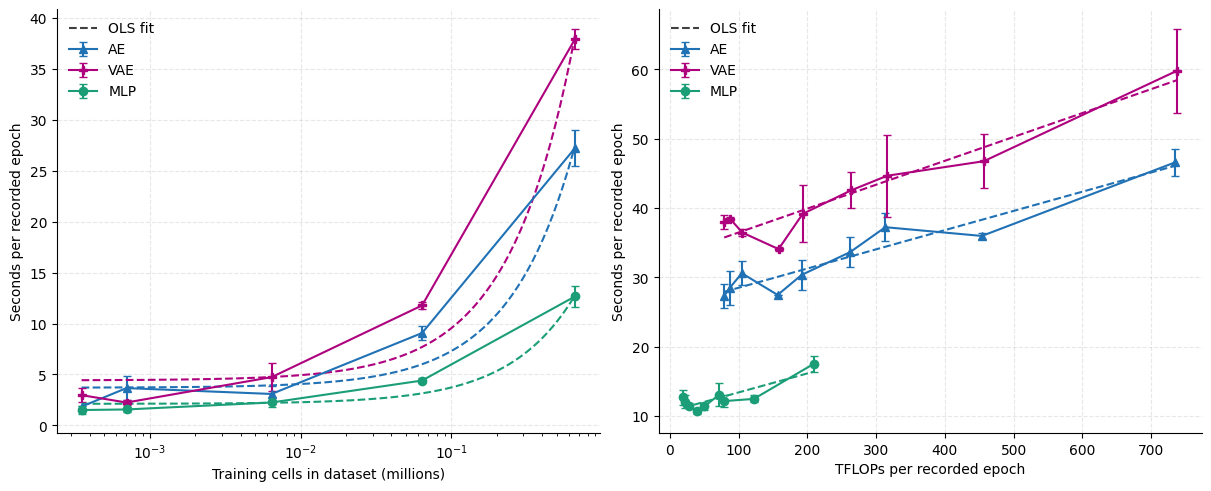

In [8]:
STYLES = {"AE": ("#2171b5", "^"), "VAE": ("#ae017e", "P"), "MLP": ("#1b9e77", "o")}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)

for family, (color, marker) in STYLES.items():
    _, latent = FLOPS_FIT_ON[family]
    panels = [
        (cell_points[(cell_points.family == family) & (cell_points.latent_dim == latent)],
         cell_models[family, latent], "cells_million"),
        (flop_points[flop_points.family == family], flop_models[family], "tflops"),
    ]
    for ax, (rows, fit, x) in zip(axes, panels):
        rows = rows.sort_values(x)
        ax.errorbar(rows[x], rows.seconds_per_epoch, yerr=rows.sd,
                    color=color, marker=marker, capsize=3, label=family)
        xs = np.geomspace(rows[x].min(), rows[x].max(), 200)
        ax.plot(xs, line(fit, xs), color=color, ls="--")

for ax, xlabel in zip(axes, ["Training cells in dataset (millions)", "TFLOPs per recorded epoch"]):
    ax.plot([], [], color="0.25", ls="--", label="OLS fit")
    ax.set(xlabel=xlabel, ylabel="Seconds per recorded epoch")
    ax.grid(ls="--", alpha=0.3)
    ax.legend(loc="upper left", frameon=False)
axes[0].set_xscale("log")
plt.show()


### 3b. Extrapolation check

- refit cell-count line without the largest dataset
- predict the largest dataset


In [9]:
checks = []
for (family, latent), g in cell_points.groupby(["family", "latent_dim"]):
    g = g.sort_values("n_train")
    fit = smf.ols("seconds_per_epoch ~ cells_million", data=g.iloc[:-1]).fit()
    largest = g.iloc[-1]
    checks.append({"family": family, "latent_dim": latent,
                   "observed": largest.seconds_per_epoch,
                   "predicted": line(fit, largest.cells_million)})
checks = pd.DataFrame(checks)
checks["error_%"] = 100 * (checks.predicted / checks.observed - 1)
display(checks)


,family,latent_dim,observed,predicted,error_%
0,AE,10,25.814,56.253,117.916
1,AE,32,26.243,65.138,148.214
2,AE,128,26.408,68.140,158.022
3,AE,512,27.362,77.023,181.499
4,AE,2048,27.265,69.335,154.301
5,MLP,128,8.961,21.573,140.743
6,MLP,512,9.404,21.340,126.921
7,MLP,1152,10.825,25.433,134.943
8,MLP,1280,10.585,24.804,134.322
9,MLP,2058,12.676,30.426,140.036


## 4. Target datasets

- train / val / test cells per split
- preserved cell counts used by the saved estimates


In [10]:
targets = pd.read_csv(ROOT / "runtime/estimates/dataset_cells.csv")
display(targets)


,dataset,split,n_train,n_val,n_test
0,LuCA,split01,765577,34143,92576
1,LuCA,split02,475558,137289,279449
2,LuCA,split03,647044,120608,124644
3,Tahoe,split01,60873422,15750461,12799374
4,Tahoe,split02,63120988,12119855,14182414
5,Tahoe,split03,62445803,13535257,13442197
6,PBMC,split01,6599788,1593653,1504533
7,PBMC,split02,6806908,1346132,1544934
8,PBMC,split03,6734457,1415009,1548508


## 5. Estimate

$$\text{s/epoch} = \left(\text{slope}_1 \times \frac{N}{10^6} + \text{intercept}_1\right) \times \frac{\text{slope}_2 \times F_\text{target} + \text{intercept}_2 \times \left(p \times \frac{256}{B} + 1 - p\right)}{\text{slope}_2 \times F_\text{ref} + \text{intercept}_2}$$

- $N$: training cells
- $F_\text{target}$: TFLOPs/epoch of the model config at the LuCA reference size
- $F_\text{ref}$: TFLOPs/epoch of the same model at 1024x1
  - MLP: both use the recorded training/validation coverage of that model's LuCA 1024x1 runs
- $B$: training batch size (timing runs: 256)
- $p$ = 0.87: share of intercept_2 that scales with 256 / B
  - estimated from real PBMC / Tahoe runs

GPU hours = s/epoch x epochs / 3600

- epochs: median on full LuCA
  - width 1024 / 2048 / 4096 x depth 1 / 2 / 4
  - mlAE, nlscVI (latent 2048), SE


In [11]:
flops_by_model = flops.set_index(KEYS)

# -- Model configs to estimate: (model, latent, width, depth) ---------------
model_configs = (
    [(m, z, h, d) for m, z, h, d in product(E2E_MODELS, E2E_LATENTS, WIDTHS, DEPTHS)]
  + [(m, z, h, d) for (m, z), h, d in product(FM_LATENTS.items(), WIDTHS, DEPTHS)]
)

# -- Estimated epoch count from the historical runs with the current loaders
grid_runs   = runs.merge(pd.DataFrame(model_configs, columns=KEYS), on=KEYS)
grid_runs   = grid_runs[grid_runs.n_train == META["n_train"]]
is_fit_model = [(m, z) in FLOPS_FIT_ON.values() for m, z in zip(grid_runs.model, grid_runs.latent_dim)]
median_epochs = grid_runs[is_fit_model].groupby("family").epochs.median()
print("Median epochs:", median_epochs.to_dict())


def seconds_per_epoch(model, latent, width, depth, n_train, n_val, batch_size):
    family = MODEL_FAMILY[model]

    # 1. Cell-count fit: seconds/epoch of this model at 1024x1 on n_train cells
    baseline = line(cell_models[family, latent], n_train / 1e6)

    # 2. Architecture costs at LuCA's reference size, using recorded MLP work.
    #    Validation is rescaled to this dataset's val/train ratio.
    f_train, f_total = flops_by_model.loc[(model, latent, width, depth), ["train_dense_tflops_per_epoch", "tflops"]]
    f_ref = flops_by_model.loc[(model, latent, 1024, 1), "tflops"]
    train_scale, val_work_scale = 1.0, 1.0
    if family == "MLP":
        # Compare architectures at the same 1024x1 workload; the grid is already adjusted.
        cell_columns = ["train_cells_per_epoch", "val_cells_per_epoch"]
        ref_cells = flops_by_model.loc[(model, latent, 1024, 1), cell_columns]
        model_cells = flops_by_model.loc[(model, latent, width, depth), cell_columns]
        train_scale, val_work_scale = ref_cells / model_cells
    val_scale = (n_val / n_train) / (META["n_val"] / META["n_train"])
    f_target = train_scale * f_train + val_work_scale * val_scale * (f_total - f_train)

    # 3. FLOPs fit: scale baseline by how much slower (width, depth) is than 1024x1;
    #    the per-step share of the intercept shrinks with larger batches
    intercept, slope = flop_models[family].params
    batch_scale = PER_STEP_SHARE * TIMING_BATCH / batch_size + 1 - PER_STEP_SHARE
    t_target = slope * f_target + intercept * batch_scale
    t_ref    = slope * f_ref    + intercept
    return baseline * t_target / t_ref


# -- Every split x every model config ----------------------------------------
rows = []
for t in targets.itertuples():
    for m, z, h, d in model_configs:
        family = MODEL_FAMILY[m]
        batch  = BATCH_SIZE[t.dataset][family]
        spe = seconds_per_epoch(m, z, h, d, t.n_train, t.n_val, batch)
        rows.append({
            "dataset": t.dataset, "split": t.split, "family": family,
            "model": m, "latent_dim": z, "hidden_dim": h, "depth": d, "batch_size": batch,
            "seconds_per_epoch": spe,
            "epochs_assumed": median_epochs[family],
            "gpu_hours":         spe * median_epochs[family] / 3600,
        })
estimates = pd.DataFrame(rows)
assert (estimates.gpu_hours > 0).all()
print(f"{len(model_configs)} model configs x {len(targets)} splits = {len(estimates)} estimates")


Median epochs: {'AE': 90.0, 'MLP': 134.0, 'VAE': 50.0}
204 model configs x 9 splits = 1836 estimates


## 6. Embedding extraction

- **s = slope_3 x (cells / 1 000 000) + intercept_3**
  - fit per FM, LuCA 500 cells -> 892k
- one pass per FM over all cells (train + val + test)
  - splits share the same cells -> embed once per dataset


In [12]:
embed_runs = pd.read_csv(ROOT / "runtime/02_foundation_model/measurements/embed_runtime.csv")
embed_runs = embed_runs[embed_runs.exit_code == 0]
embed_runs["seconds"] = embed_runs.embed_seconds + embed_runs.combine_seconds
embed_runs["cells_million"] = embed_runs.n_cells / 1e6

embed_models = {
    m: smf.ols("seconds ~ cells_million", data=g).fit()
    for m, g in embed_runs.groupby("model")
}
print("Embedding fits"); display(fit_table(embed_models, "model"))

all_cells = (targets.n_train + targets.n_val + targets.n_test).groupby(targets.dataset).first()
embedding = pd.DataFrame([
    {"dataset": dataset, "model": m, "gpu_hours": line(fit, n / 1e6) / 3600}
    for dataset, n in all_cells.items() for m, fit in embed_models.items()
])
display(embedding.pivot_table(index="model", columns="dataset", values="gpu_hours"))


Embedding fits


,slope,slope_95_low,slope_95_high,intercept,r2,n_points
model,,,,,,
Geneformer,"13,663.916","10,688.760","16,639.072","2,728.209",0.883,15
SE,"8,531.162","7,899.053","9,163.271",845.746,0.985,15
UCE,"49,670.520","47,062.257","52,278.783","3,230.616",0.992,15
scConcept,496.549,426.208,566.891,124.181,0.947,15
scFoundation,"11,417.062","10,988.201","11,845.923",70.367,0.996,15
scGPT,"1,724.673","1,261.923","2,187.422",518.430,0.833,15
scimilarity,413.755,354.776,472.734,70.597,0.946,15


dataset,LuCA,PBMC,Tahoe
model,,,
Geneformer,4.145,37.567,340.167
SE,2.349,23.217,212.147
UCE,13.209,134.704,"1,234.703"
scConcept,0.158,1.372,12.369
scFoundation,2.849,30.776,283.617
scGPT,0.571,4.790,42.985
scimilarity,0.122,1.134,10.297


## 7. PCA

- **s = slope_4 x (cells / 1 000 000) + intercept_4**
  - fit per latent, LuCA 353 -> 661k train cells
- no epochs, no width x depth
- one fit per split and latent


In [13]:
pca_runs = pd.read_csv(ROOT / "runtime/01_end_to_end/measurements/runtime.csv")
pca_runs = pca_runs[(pca_runs.model == "PCA") & (pca_runs.exit_code == 0)]
pca_runs["cells_million"] = pca_runs.n_train / 1e6

pca_models = {
    z: smf.ols("seconds ~ cells_million", data=g).fit()
    for z, g in pca_runs.groupby("latent_dim")
}
print("PCA fits"); display(fit_table(pca_models, "latent_dim"))

pca = pd.DataFrame([
    {"dataset": t.dataset, "split": t.split, "latent_dim": z,
     "gpu_hours": line(fit, t.n_train / 1e6) / 3600}
    for t in targets.itertuples() for z, fit in pca_models.items()
])
display(pca.pivot_table(index="latent_dim", columns="dataset", values="gpu_hours", aggfunc="sum"))


PCA fits


,slope,slope_95_low,slope_95_high,intercept,r2,n_points
latent_dim,,,,,,
10,19.924,9.803,30.046,28.658,0.582,15
32,15.156,4.172,26.140,28.253,0.406,15
128,3.614,-11.474,18.702,30.238,0.020,15
512,13.986,10.672,17.299,24.669,0.898,12
2048,15.699,5.299,26.099,27.029,0.645,9


dataset,LuCA,PBMC,Tahoe
latent_dim,,,
10,0.034,0.135,1.056
32,0.031,0.108,0.808
128,0.027,0.045,0.212
512,0.028,0.099,0.745
2048,0.031,0.110,0.836


## 8. Budget summary

- single-H100 GPU hours
- summed over splits, model configs, PCA latents, and FMs
- excludes evaluation and queueing


In [14]:
by_dataset = estimates.pivot_table(index="dataset", columns="family",
                                   values="gpu_hours", aggfunc="sum")[["AE", "VAE", "MLP"]]
by_dataset.insert(2, "PCA", pca.groupby("dataset").gpu_hours.sum())
by_dataset.insert(3, "Embedding", embedding.groupby("dataset").gpu_hours.sum())
by_dataset["Total GPU hours"]  = by_dataset.sum(axis=1)
by_dataset["GPU days"]         = by_dataset["Total GPU hours"] / 24
by_dataset.loc["All datasets"] = by_dataset.sum()
display(by_dataset)

OUT = ROOT / "runtime/estimates"
OUT.mkdir(parents=True, exist_ok=True)
estimates.to_csv(OUT / "training_estimates.csv", index=False)
pca.to_csv(OUT / "pca_estimates.csv", index=False)
embedding.to_csv(OUT / "embedding_estimates.csv", index=False)
by_dataset.to_csv(OUT / "budget_by_dataset.csv")
print(f"Saved CSVs to {OUT}")

if n_missing:
    print(f"PROVISIONAL: {n_missing} model complexity runs missing; rerun when the grid completes.")


family,AE,VAE,PCA,Embedding,MLP,Total GPU hours,GPU days
dataset,,,,,,,
LuCA,136.865,96.097,0.152,23.403,109.785,366.302,15.263
PBMC,446.649,309.199,0.498,233.560,965.060,"1,954.966",81.457
Tahoe,"5,723.581","2,832.581",3.657,"2,136.284","2,676.391","13,372.494",557.187
All datasets,"6,307.095","3,237.877",4.307,"2,393.247","3,751.235","15,693.762",653.907


Saved CSVs to ../runtime/estimates


Notes:

- timings up to 661k cells (full LuCA)
  - PBMC (approx. 6.7M) and Tahoe (approx. 61M) are extrapolated
- HVG genes only (~5–6k); all-gene decoders are slower
- rough planning numbers


In [15]:
# Average estimated time per method (GPU hours)
# Average configurations within each split, then average across splits.
average_time = (
    estimates.groupby(["dataset", "split", "family"]).gpu_hours.mean()
    .groupby(level=["dataset", "family"]).mean().unstack("family")
)
average_time["PCA"] = (
    pca.groupby(["dataset", "split"]).gpu_hours.mean()
    .groupby(level="dataset").mean()
)
# Embedding is computed once per dataset; average across the seven FMs.
average_time["Embedding"] = embedding.groupby("dataset").gpu_hours.mean()
average_time = average_time[["AE", "VAE", "PCA", "Embedding", "MLP"]]
average_time["Total GPU hours"] = average_time.sum(axis=1)
average_time["GPU days"] = average_time["Total GPU hours"] / 24
display(average_time)
average_time.to_csv(OUT / "average_time_by_dataset.csv")


family,AE,VAE,PCA,Embedding,MLP,Total GPU hours,GPU days
dataset,,,,,,,
LuCA,0.760,0.534,0.010,3.343,0.436,5.083,0.212
PBMC,2.481,1.718,0.033,33.366,3.830,41.428,1.726
Tahoe,31.798,15.737,0.244,305.183,10.621,363.582,15.149
